Inspect a dataset instead of immediately assuming its structure.

In [1]:
import pandas as pd
import zipfile
from pathlib import Path

zip_path = Path("Production_Crops_Livestock_E_Africa.zip")

with zipfile.ZipFile(zip_path, "r") as archive:
    df = pd.read_csv(
        archive.open(
            "Production_Crops_Livestock_E_Africa_NOFLAG.csv"
        )
    )

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nData types:")
print(df.dtypes.head(12))

Dataset shape: (14750, 73)

Column names:
['Area Code', 'Area Code (M49)', 'Area', 'Item Code', 'Item Code (CPC)', 'Item', 'Element Code', 'Element', 'Unit', 'Y1961', 'Y1962', 'Y1963', 'Y1964', 'Y1965', 'Y1966', 'Y1967', 'Y1968', 'Y1969', 'Y1970', 'Y1971', 'Y1972', 'Y1973', 'Y1974', 'Y1975', 'Y1976', 'Y1977', 'Y1978', 'Y1979', 'Y1980', 'Y1981', 'Y1982', 'Y1983', 'Y1984', 'Y1985', 'Y1986', 'Y1987', 'Y1988', 'Y1989', 'Y1990', 'Y1991', 'Y1992', 'Y1993', 'Y1994', 'Y1995', 'Y1996', 'Y1997', 'Y1998', 'Y1999', 'Y2000', 'Y2001', 'Y2002', 'Y2003', 'Y2004', 'Y2005', 'Y2006', 'Y2007', 'Y2008', 'Y2009', 'Y2010', 'Y2011', 'Y2012', 'Y2013', 'Y2014', 'Y2015', 'Y2016', 'Y2017', 'Y2018', 'Y2019', 'Y2020', 'Y2021', 'Y2022', 'Y2023', 'Y2024']

First five rows:


,Area Code,Area Code (M49),Area,Item Code,Item Code (CPC),Item,Element Code,Element,Unit,Y1961,...,Y2015,Y2016,Y2017,Y2018,Y2019,Y2020,Y2021,Y2022,Y2023,Y2024
0,4,'012,Algeria,221,'01371,"Almonds, in shell",5312,Area harvested,ha,13300.0,...,40403.0,49983.0,50100.0,35626.00,35380.0,34542.0,32492.0,36586.00,38540.00,36926.00
1,4,'012,Algeria,221,'01371,"Almonds, in shell",5412,Yield,kg/ha,451.1,...,1893.0,1322.3,1236.2,1605.90,2046.7,1761.1,1706.5,1727.70,1809.40,1855.40
2,4,'012,Algeria,221,'01371,"Almonds, in shell",5510,Production,t,6000.0,...,76482.0,66095.0,61934.0,57212.58,72412.0,60832.0,55448.0,63210.52,69734.97,68512.76
3,4,'012,Algeria,515,'01341,Apples,5312,Area harvested,ha,3400.0,...,41011.0,46070.0,44620.0,33653.00,32989.0,33025.0,31171.0,32848.00,32852.00,31875.00
4,4,'012,Algeria,515,'01341,Apples,5412,Yield,kg/ha,4529.4,...,11008.6,10871.6,11076.7,14495.20,16939.9,17163.5,16756.3,16790.40,17704.20,18563.30



Data types:
Area Code            int64
Area Code (M49)     object
Area                object
Item Code            int64
Item Code (CPC)     object
Item                object
Element Code         int64
Element             object
Unit                object
Y1961              float64
Y1962              float64
Y1963              float64
dtype: object


The dataset currently has a wide format: each year is stored in a separate column, such as Y1961, Y1962 and Y1963.

The identifier columns tell us what each observation represents:
Column	Meaning
Area	Country or reporting area
Item	Crop or agricultural product
Element	Measure, such as Production, Yield or Area harvested
Unit	Measurement unit
`Y196

Step 2: Convert the dataset from wide to long format

In [2]:
# 1. Identify the annual columns
year_cols = [
    col for col in df.columns
    if col.startswith("Y") and col[1:].isdigit()
]

# 2. Keep all non-year columns as identifiers
id_cols = [
    col for col in df.columns
    if col not in year_cols
]

print("Number of year columns:", len(year_cols))
print("First five year columns:", year_cols[:5])
print("Last five year columns:", year_cols[-5:])

# 3. Reshape the dataset
df_long = df.melt(
    id_vars=id_cols,
    value_vars=year_cols,
    var_name="Year",
    value_name="Value"
)

# 4. Convert year labels such as Y1961 into numeric years
df_long["Year"] = (
    df_long["Year"]
    .str.replace("Y", "", regex=False)
    .astype(int)
)

# 5. Ensure the observation values are numeric
df_long["Value"] = pd.to_numeric(
    df_long["Value"],
    errors="coerce"
)

# 6. Inspect the result
print("\nOriginal shape:", df.shape)
print("Reshaped shape:", df_long.shape)

display(df_long.head(10))


Number of year columns: 64
First five year columns: ['Y1961', 'Y1962', 'Y1963', 'Y1964', 'Y1965']
Last five year columns: ['Y2020', 'Y2021', 'Y2022', 'Y2023', 'Y2024']

Original shape: (14750, 73)
Reshaped shape: (944000, 11)


,Area Code,Area Code (M49),Area,Item Code,Item Code (CPC),Item,Element Code,Element,Unit,Year,Value
0,4,'012,Algeria,221,'01371,"Almonds, in shell",5312,Area harvested,ha,1961,13300.0
1,4,'012,Algeria,221,'01371,"Almonds, in shell",5412,Yield,kg/ha,1961,451.1
2,4,'012,Algeria,221,'01371,"Almonds, in shell",5510,Production,t,1961,6000.0
3,4,'012,Algeria,515,'01341,Apples,5312,Area harvested,ha,1961,3400.0
4,4,'012,Algeria,515,'01341,Apples,5412,Yield,kg/ha,1961,4529.4
5,4,'012,Algeria,515,'01341,Apples,5510,Production,t,1961,15400.0
6,4,'012,Algeria,526,'01343,Apricots,5312,Area harvested,ha,1961,4200.0
7,4,'012,Algeria,526,'01343,Apricots,5412,Yield,kg/ha,1961,3028.6
8,4,'012,Algeria,526,'01343,Apricots,5510,Production,t,1961,12720.0
9,4,'012,Algeria,366,'01216,Artichokes,5312,Area harvested,ha,1961,5000.0


Validate the transformation

In [3]:

# Check the data types
print(df_long.dtypes)

# Check year coverage
print(
    "Year range:",
    df_long["Year"].min(),
    "to",
    df_long["Year"].max()
)

# Check missing observations
print(
    "Missing values:",
    df_long["Value"].isna().sum()
)

print(
    "Missing percentage:",
    round(df_long["Value"].isna().mean() * 100, 2),
    "%"
)

# Inspect available measures
print("\nAvailable elements:")
print(sorted(df_long["Element"].dropna().unique()))

# Inspect available units
print("\nAvailable units:")
print(sorted(df_long["Unit"].dropna().unique()))


Area Code            int64
Area Code (M49)     object
Area                object
Item Code            int64
Item Code (CPC)     object
Item                object
Element Code         int64
Element             object
Unit                object
Year                 int64
Value              float64
dtype: object
Year range: 1961 to 2024
Missing values: 143243
Missing percentage: 15.17 %

Available elements:
['Area harvested', 'Laying', 'Milk Animals', 'Producing Animals/Slaughtered', 'Production', 'Stocks', 'Yield', 'Yield/Carcass Weight']

Available units:
['1000 An', '1000 No', 'An', 'No', 'No/An', 'g/An', 'ha', 'kg/An', 'kg/ha', 't']


Check for duplicate observations

In [4]:
# Each area, item, element and year should normally
# identify one observation in this dataset.

key_cols = [
    "Area Code",
    "Item Code",
    "Element Code",
    "Year"
]

duplicate_count = df_long.duplicated(
    subset=key_cols,
    keep=False
).sum()

print("Rows involved in duplicate keys:", duplicate_count)


Rows involved in duplicate keys: 0


Step 3 — Interpret the data-quality results

-Missing observations
15.17%    143,243 missing values
Duplicate keys  0 - No duplicate combinations detected
-Year coverage is correct - the reshaped data spans 1961–2024, matching the annual columns in the original dataset.
Missing values need investigation - A missing value does not necessarily mean zero production. It could reflect an unreported observation or another data-availability issue.
One subtle point: the zero-duplicate result applies to the key columns we tested. It tells us that those particular combinations are unique; it does not guarantee that every observation is correct.

Step 3.1 — Investigate missing values

In [5]:

# 1. Overall missingness by agricultural measure
missing_by_element = (
    df_long.groupby("Element")["Value"]
    .agg(
        total_rows="size",
        missing_values=lambda x: x.isna().sum()
    )
)

missing_by_element["missing_pct"] = (
    missing_by_element["missing_values"]
    / missing_by_element["total_rows"] * 100
).round(2)

display(missing_by_element.sort_values("missing_pct", ascending=False))


# 2. Missingness by year
missing_by_year = (
    df_long.groupby("Year")["Value"]
    .agg(
        total_rows="size",
        missing_values=lambda x: x.isna().sum()
    )
)

missing_by_year["missing_pct"] = (
    missing_by_year["missing_values"]
    / missing_by_year["total_rows"] * 100
).round(2)

display(missing_by_year.head(10))


# 3. Missingness by country
missing_by_area = (
    df_long.groupby("Area")["Value"]
    .agg(
        total_rows="size",
        missing_values=lambda x: x.isna().sum()
    )
)

missing_by_area["missing_pct"] = (
    missing_by_area["missing_values"]
    / missing_by_area["total_rows"] * 100
).round(2)

display(missing_by_area.sort_values("missing_values", ascending=False).head(10))


,total_rows,missing_values,missing_pct
Element,,,
Yield,193792,38912,20.08
Area harvested,189952,35782,18.84
Production,358336,54103,15.10
Milk Animals,11968,1207,10.09
Stocks,41920,3164,7.55
Yield/Carcass Weight,64192,4739,7.38
Producing Animals/Slaughtered,76416,4951,6.48
Laying,7424,385,5.19


,total_rows,missing_values,missing_pct
Year,,,
1961,14750,3283,22.26
1962,14750,3282,22.25
1963,14750,3278,22.22
1964,14750,3278,22.22
1965,14750,3276,22.21
1966,14750,3265,22.14
1967,14750,3261,22.11
1968,14750,3246,22.01
1969,14750,3234,21.93


,total_rows,missing_values,missing_pct
Area,,,
Sudan,17216,13749,79.86
Ethiopia,23488,12159,51.77
Ethiopia PDR,20032,10266,51.25
South Sudan,11200,9109,81.33
Réunion,17856,6526,36.55
Eritrea,11392,5705,50.08
Malawi,20736,5243,25.28
Sudan (former),18432,5108,27.71
Zimbabwe,24960,4475,17.93


Three findings stand out:
- Kenya has 11.94% missing values across its rows, substantially lower than the percentages shown for several other areas.
- Sudan and South Sudan have very high missingness, which could make comparisons based on their full historical records misleading.
- Ethiopia PDR and Ethiopia are separate entries in the dataset. We must respect the historical geographic definitions rather than combining their records without investigation.
Remember that missingness alone does not tell us whether a dataset is biased. We need to determine which years, crops and measures are missing.

Step 3.2 — Check actual zero values

In [6]:

# Count missing, zero and positive observations
value_status = pd.Series({
    "Missing": df_long["Value"].isna().sum(),
    "Zero": df_long["Value"].eq(0).sum(),
    "Positive": df_long["Value"].gt(0).sum(),
    "Negative": df_long["Value"].lt(0).sum()
})

display(value_status.to_frame("Count"))


,Count
Missing,143243
Zero,12247
Positive,788510
Negative,0


The results are:
Value status	Count	Interpretation
Missing	143,243	No numeric value recorded
Zero	12,247	Explicitly recorded as zero
Positive	788,510	Positive reported values
Negative	0	No negative numeric values
Important: A missing value is not the same as zero. A missing value may indicate unavailable or unreported data; a zero may be a genuine reported value. We should not automatically replace missing values with zero because that would distort production trends and averages.

Step 3.3 — Inspect the original observation flags

In [7]:

import zipfile
import pandas as pd

zip_path = "Production_Crops_Livestock_E_Africa.zip"

with zipfile.ZipFile(zip_path, "r") as archive:
    df_flags = pd.read_csv(
        archive.open("Production_Crops_Livestock_E_Africa.csv")
    )

print("Flagged dataset shape:", df_flags.shape)
print("\nColumns:")
print(df_flags.columns.tolist())

display(df_flags.head())


Flagged dataset shape: (14750, 201)

Columns:
['Area Code', 'Area Code (M49)', 'Area', 'Item Code', 'Item Code (CPC)', 'Item', 'Element Code', 'Element', 'Unit', 'Y1961', 'Y1961F', 'Y1961N', 'Y1962', 'Y1962F', 'Y1962N', 'Y1963', 'Y1963F', 'Y1963N', 'Y1964', 'Y1964F', 'Y1964N', 'Y1965', 'Y1965F', 'Y1965N', 'Y1966', 'Y1966F', 'Y1966N', 'Y1967', 'Y1967F', 'Y1967N', 'Y1968', 'Y1968F', 'Y1968N', 'Y1969', 'Y1969F', 'Y1969N', 'Y1970', 'Y1970F', 'Y1970N', 'Y1971', 'Y1971F', 'Y1971N', 'Y1972', 'Y1972F', 'Y1972N', 'Y1973', 'Y1973F', 'Y1973N', 'Y1974', 'Y1974F', 'Y1974N', 'Y1975', 'Y1975F', 'Y1975N', 'Y1976', 'Y1976F', 'Y1976N', 'Y1977', 'Y1977F', 'Y1977N', 'Y1978', 'Y1978F', 'Y1978N', 'Y1979', 'Y1979F', 'Y1979N', 'Y1980', 'Y1980F', 'Y1980N', 'Y1981', 'Y1981F', 'Y1981N', 'Y1982', 'Y1982F', 'Y1982N', 'Y1983', 'Y1983F', 'Y1983N', 'Y1984', 'Y1984F', 'Y1984N', 'Y1985', 'Y1985F', 'Y1985N', 'Y1986', 'Y1986F', 'Y1986N', 'Y1987', 'Y1987F', 'Y1987N', 'Y1988', 'Y1988F', 'Y1988N', 'Y1989', 'Y1989F', 'Y1989N

,Area Code,Area Code (M49),Area,Item Code,Item Code (CPC),Item,Element Code,Element,Unit,Y1961,...,Y2021N,Y2022,Y2022F,Y2022N,Y2023,Y2023F,Y2023N,Y2024,Y2024F,Y2024N
0,4,'012,Algeria,221,'01371,"Almonds, in shell",5312,Area harvested,ha,13300.0,...,NaN,36586.00,I,NaN,38540.00,I,NaN,36926.00,I,NaN
1,4,'012,Algeria,221,'01371,"Almonds, in shell",5412,Yield,kg/ha,451.1,...,NaN,1727.70,E,NaN,1809.40,E,NaN,1855.40,E,NaN
2,4,'012,Algeria,221,'01371,"Almonds, in shell",5510,Production,t,6000.0,...,NaN,63210.52,I,NaN,69734.97,I,NaN,68512.76,I,NaN
3,4,'012,Algeria,515,'01341,Apples,5312,Area harvested,ha,3400.0,...,NaN,32848.00,I,NaN,32852.00,I,NaN,31875.00,I,NaN
4,4,'012,Algeria,515,'01341,Apples,5412,Yield,kg/ha,4529.4,...,NaN,16790.40,E,NaN,17704.20,E,NaN,18563.30,E,NaN


The original dataset has columns such as Y2022, Y2022F, and Y2022N.
- Y2022: the numerical observation for 2022.
- Y2022F: the observation flag, which can qualify the reported value. For example, E commonly indicates an estimated value and I an imputed value.
- Y2022N: a separate flag field that may be blank or contain additional status information.
The flags matter because a value can be numeric without being a directly reported observation. We should inspect the flags before deciding how to handle them.

Step 3.4 — Inspect the flag meanings

In [1]:

import zipfile
import pandas as pd
from pathlib import Path

zip_path = Path("Production_Crops_Livestock_E_Africa.zip")

with zipfile.ZipFile(zip_path, "r") as archive:
    print([
        name for name in archive.namelist()
        if "Flags" in name or "flags" in name
    ])
    
    flag_file = next(
        name for name in archive.namelist()
        if "Flags" in name or "flags" in name
    )
    
    flags = pd.read_csv(archive.open(flag_file))

print("Flag reference shape:", flags.shape)
display(flags.head(20))


['Production_Crops_Livestock_E_Flags.csv']
Flag reference shape: (5, 2)


,Flag,Description
0,A,Official figure
1,E,Estimated value
2,I,Value imputed by a receiving agency
3,M,Missing value; data cannot exist
4,X,Figure from external organization


Flag	Meaning	How we should treat it
A	Official figure	Retain; identify as official
E	Estimated value	Retain, but distinguish from official figures
I	Imputed by a receiving agency	Retain, but flag for quality assessment
M	Missing; data cannot exist	Investigate alongside the numeric value
X	Figure from an external organization	Retain, but identify its source category
Our decision: We will not automatically delete estimated, imputed, or externally sourced observations. They may be important for understanding agricultural trends, especially where official data is limited. Instead, we'll preserve the flags and assess their impact on our findings.

Step 3.5 — Inspect Kenya's crop data quality

In [2]:

import pandas as pd
import zipfile
from pathlib import Path

zip_path = Path("Production_Crops_Livestock_E_Africa.zip")

with zipfile.ZipFile(zip_path, "r") as archive:
    df_flags = pd.read_csv(
        archive.open("Production_Crops_Livestock_E_Africa.csv")
    )

# Select Kenya's observations
kenya_flags = df_flags[df_flags["Area"] == "Kenya"].copy()

print("Kenya dataset shape:", kenya_flags.shape)

# Identify all observation-flag columns
flag_cols = [
    col for col in kenya_flags.columns
    if col.endswith("F") and col.startswith("Y")
]

print("Number of flag columns:", len(flag_cols))

# Count flag occurrences across Kenya's observations
flag_counts = (
    kenya_flags[flag_cols]
    .stack()
    .value_counts()
    .rename_axis("Flag")
    .reset_index(name="Count")
)

display(flag_counts)


Kenya dataset shape: (417, 201)
Number of flag columns: 64


,Flag,Count
0,E,10606
1,A,8945
2,I,3274
3,M,731
4,X,677


The dataset contains 417 rows for Kenya and 64 annual flag columns, covering 1961–2024.
Flag	Count	Share of recorded flag entries
E — Estimated	10,606	43.7%
A — Official	8,945	36.9%
I — Imputed	3,274	13.5%
M — Missing	731	3.0%
X — External	677	2.8%
These percentages use the 24,233 flag entries in your table as the denominator. They describe flag entries, not the proportion of Kenya's production or the proportion of unique observations.
What this means for our project
- Estimated figures are the most common flag category in this count.
- Official figures also make up a substantial share.
- Imputed observations deserve attention when evaluating how reliable particular trends are.
- The M flag means the data cannot exist according to the flag definition you retrieved. We should inspect how it appears alongside numeric values rather than assuming it always corresponds to a blank cell.
- We should not discard all estimated or imputed values; doing so could leave gaps in our historical analysis.
One technical note: the flag counts add up to 24,233, but Kenya has 417 rows × 64 flag columns = 26,688 possible cells. Some cells are blank and therefore aren't included in the flag counts.

Step 3.6 — Check the quality of our three main measures

In [ ]:

import pandas as pd
import zipfile
from pathlib import Path

zip_path = Path("Production_Crops_Livestock_E_Africa.zip")

with zipfile.ZipFile(zip_path, "r") as archive:
    df = pd.read_csv(
        archive.open("Production_Crops_Livestock_E_Africa_NOFLAG.csv")
    )

# Identify annual columns such as Y1961, Y1962, ..., Y2024
year_cols = [
    col for col in df.columns
    if col.startswith("Y") and col[1:].isdigit()
]

# Keep all non-year columns as identifiers
id_cols = [col for col in df.columns if col not in year_cols]

# Convert from wide format to long format
df_long = df.melt(
    id_vars=id_cols,
    value_vars=year_cols,
    var_name="Year",
    value_name="Value"
)

df_long["Year"] = (
    df_long["Year"]
    .str.replace("Y", "", regex=False)
    .astype(int)
)

df_long["Value"] = pd.to_numeric(
    df_long["Value"], errors="coerce"
)

print("Original dataset shape:", df.shape)
print("Long-format dataset shape:", df_long.shape)
print("Year range:", df_long["Year"].min(), "to", df_long["Year"].max())

display(df_long.head())


In [5]:

# Focus on Kenya and the three main crop measures
crop_elements = ["Production", "Area harvested", "Yield"]

kenya_crop_measures = df_long[
    (df_long["Area"] == "Kenya") &
    (df_long["Element"].isin(crop_elements))
].copy()

# Summarise completeness and numeric values by measure
quality_summary = (
    kenya_crop_measures
    .groupby(["Element", "Unit"])["Value"]
    .agg(
        total_rows="size",
        missing_values=lambda x: x.isna().sum(),
        zero_values=lambda x: x.eq(0).sum(),
        positive_values=lambda x: x.gt(0).sum()
    )
    .reset_index()
)

quality_summary["missing_pct"] = (
    quality_summary["missing_values"] /
    quality_summary["total_rows"] * 100
).round(2)

display(quality_summary)


,Element,Unit,total_rows,missing_values,zero_values,positive_values,missing_pct
0,Area harvested,ha,6144,1044,0,5100,16.99
1,Production,1000 No,64,0,0,64,0.00
2,Production,t,10304,1090,235,8979,10.58
3,Yield,No/An,64,0,0,64,0.00
4,Yield,kg/ha,6144,1044,0,5100,16.99


The results show the following for Kenya:
Measure	Unit	Missing	Missing %
Area harvested	ha	1,044 / 6,144	16.99%
Production	t	1,090 / 10,304	10.58%
Yield	kg/ha	1,044 / 6,144	16.99%
The rows measured in 1000 No and No/An are livestock-related measures, not the crop production measures we need. We'll exclude them from the crop analysis.
What the results tell us
- Production: About 10.58% of the Kenya crop-production records are missing.
- Area harvested and yield: About 16.99% are missing.
- Zero values: Some observations are zero. We'll retain them for now and investigate whether they are meaningful for each crop and year.
- Coverage: These percentages cover all included crop items and years, not just staple crops. They are a preliminary diagnostic, not proof that every crop has the same data quality.
One more important distinction: missing values may vary by crop and period. We shouldn't automatically remove every year with a missing observation, because that could distort historical trends.

Step 3.8 — Select the staple crops for our project

Step 3.9 — Check the exact crop names

In [6]:
# Search the item names available for Kenya
kenya_items = sorted(
    df_long.loc[df_long["Area"] == "Kenya", "Item"]
    .dropna()
    .unique()
)

keywords = ["maize", "bean", "sorghum", "millet", "cassava"]

for keyword in keywords:
    matches = [
        item for item in kenya_items
        if keyword.lower() in item.lower()
    ]
    
    print(f"\n{keyword.upper()}:")
    print(matches)



MAIZE:
['Maize (corn)', 'Oil of maize']

BEAN:
['Beans, dry', 'Broad beans and horse beans, green', 'Other beans, green', 'Soya beans']

SORGHUM:
['Sorghum']

MILLET:
['Millet']

CASSAVA:
['Cassava, fresh']


Step 4 — Build the analytical dataset
Our objective is to create a clean dataset for Kenya containing only these five crops and three measures: production, harvested area, and yield.

We'll also retain the original units and years. We won't fill missing values with zero or remove observations just because they're missing.

Step 4.1 — Filter the data

In [7]:

# 1. Define the exact crop names from FAOSTAT
selected_crops = [
    "Maize (corn)",
    "Beans, dry",
    "Sorghum",
    "Millet",
    "Cassava, fresh"
]

selected_elements = [
    "Production",
    "Area harvested",
    "Yield"
]

# 2. Filter for Kenya, selected crops, and relevant measures
df_crop = df_long[
    (df_long["Area"] == "Kenya") &
    (df_long["Item"].isin(selected_crops)) &
    (df_long["Element"].isin(selected_elements))
].copy()

# 3. Check the result
print("Filtered dataset shape:", df_crop.shape)
print("\nCrops included:")
print(sorted(df_crop["Item"].unique()))

print("\nMeasures and units:")
display(
    df_crop[["Element", "Unit"]]
    .drop_duplicates()
    .sort_values(["Element", "Unit"])
    .reset_index(drop=True)
)

print("\nYear coverage:")
print(df_crop["Year"].min(), "to", df_crop["Year"].max())

display(df_crop.head(10))


Filtered dataset shape: (960, 11)

Crops included:
['Beans, dry', 'Cassava, fresh', 'Maize (corn)', 'Millet', 'Sorghum']

Measures and units:


,Element,Unit
0,Area harvested,ha
1,Production,t
2,Yield,kg/ha



Year coverage:
1961 to 2024


,Area Code,Area Code (M49),Area,Item Code,Item Code (CPC),Item,Element Code,Element,Unit,Year,Value
6327,114,'404,Kenya,176,'01701,"Beans, dry",5312,Area harvested,ha,1961,115000.0
6328,114,'404,Kenya,176,'01701,"Beans, dry",5412,Yield,kg/ha,1961,478.3
6329,114,'404,Kenya,176,'01701,"Beans, dry",5510,Production,t,1961,55000.0
6348,114,'404,Kenya,125,'01520.01,"Cassava, fresh",5312,Area harvested,ha,1961,55000.0
6349,114,'404,Kenya,125,'01520.01,"Cassava, fresh",5412,Yield,kg/ha,1961,7636.4
6350,114,'404,Kenya,125,'01520.01,"Cassava, fresh",5510,Production,t,1961,420000.0
6447,114,'404,Kenya,56,'0112,Maize (corn),5312,Area harvested,ha,1961,750000.0
6448,114,'404,Kenya,56,'0112,Maize (corn),5412,Yield,kg/ha,1961,1253.3
6449,114,'404,Kenya,56,'0112,Maize (corn),5510,Production,t,1961,940000.0
6475,114,'404,Kenya,79,'0118,Millet,5312,Area harvested,ha,1961,75000.0


Step 4.2 — Check whether each crop has usable data

In [8]:
crop_coverage = (
    df_crop.groupby(["Item", "Element"])
    .agg(
        records=("Value", "size"),
        years_available=("Year", "nunique"),
        missing_values=("Value", lambda x: x.isna().sum()),
        zero_values=("Value", lambda x: x.eq(0).sum()),
        positive_values=("Value", lambda x: x.gt(0).sum())
    )
    .reset_index()
)

crop_coverage["missing_pct"] = (
    crop_coverage["missing_values"] /
    crop_coverage["records"] * 100
).round(2)

display(
    crop_coverage.sort_values(["Item", "Element"])
)


,Item,Element,records,years_available,missing_values,zero_values,positive_values,missing_pct
0,"Beans, dry",Area harvested,64,64,0,0,64,0.0
1,"Beans, dry",Production,64,64,0,0,64,0.0
2,"Beans, dry",Yield,64,64,0,0,64,0.0
3,"Cassava, fresh",Area harvested,64,64,0,0,64,0.0
4,"Cassava, fresh",Production,64,64,0,0,64,0.0
5,"Cassava, fresh",Yield,64,64,0,0,64,0.0
6,Maize (corn),Area harvested,64,64,0,0,64,0.0
7,Maize (corn),Production,64,64,0,0,64,0.0
8,Maize (corn),Yield,64,64,0,0,64,0.0
9,Millet,Area harvested,64,64,0,0,64,0.0


Step 5 — Analyze Kenya's crop production trends
Our first analytical question is:

How has production of these five crops changed in Kenya from 1961 to 2024?

Production alone does not tell us whether productivity improved. Production can increase because more land was harvested, yields improved, or both. We'll examine those measures separately.

Step 5.1 — Create the first chart

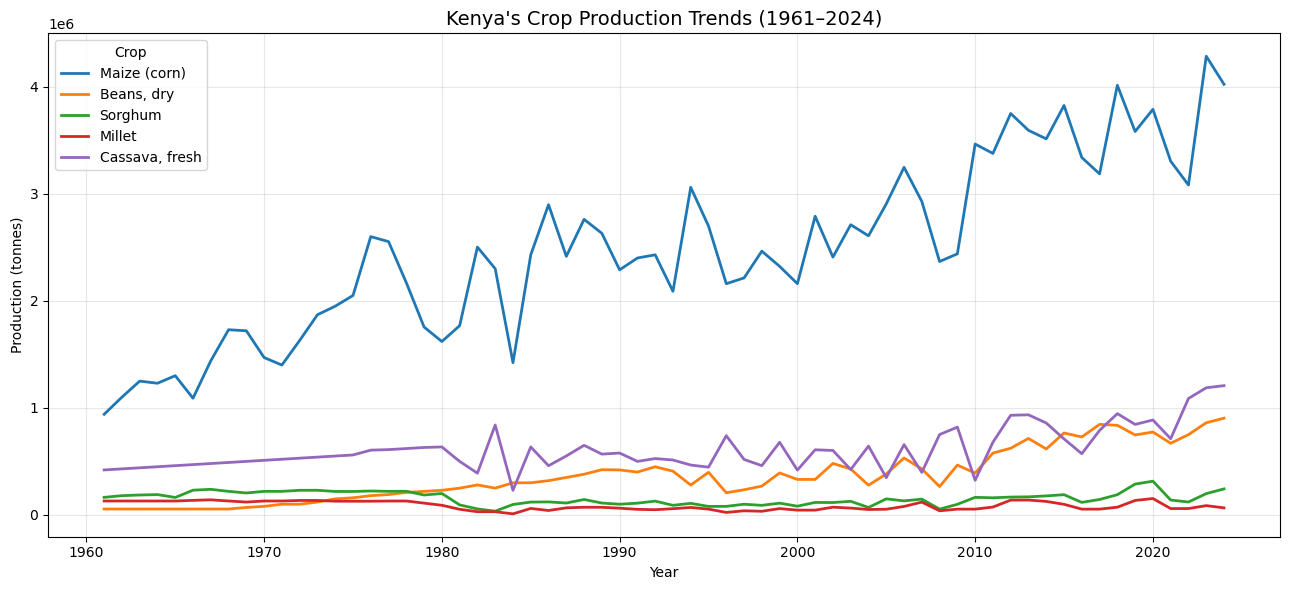

In [9]:

import matplotlib.pyplot as plt

# Filter the dataset to production only
production_df = df_crop[
    df_crop["Element"] == "Production"
].copy()

# Create a separate line for each crop
plt.figure(figsize=(13, 6))

for crop in selected_crops:
    crop_data = production_df[
        production_df["Item"] == crop
    ].sort_values("Year")

    plt.plot(
        crop_data["Year"],
        crop_data["Value"],
        label=crop,
        linewidth=2
    )

plt.title(
    "Kenya's Crop Production Trends (1961–2024)",
    fontsize=14
)
plt.xlabel("Year")
plt.ylabel("Production (tonnes)")
plt.legend(title="Crop")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Step 5.2 — Compare production in 1961 and 2024

In [10]:

# Extract production values for 1961 and 2024
endpoint_production = production_df[
    production_df["Year"].isin([1961, 2024])
].pivot(
    index="Item",
    columns="Year",
    values="Value"
)

endpoint_production = endpoint_production.rename(
    columns={
        1961: "Production_1961_t",
        2024: "Production_2024_t"
    }
)

endpoint_production["Absolute_Change_t"] = (
    endpoint_production["Production_2024_t"]
    - endpoint_production["Production_1961_t"]
)

endpoint_production["Percentage_Change"] = (
    endpoint_production["Absolute_Change_t"]
    / endpoint_production["Production_1961_t"]
    * 100
).round(2)

display(endpoint_production.reset_index())


Year,Item,Production_1961_t,Production_2024_t,Absolute_Change_t,Percentage_Change
0,"Beans, dry",55000.0,903850.98,848850.98,1543.37
1,"Cassava, fresh",420000.0,1207537.34,787537.34,187.51
2,Maize (corn),940000.0,4023000.00,3083000.00,327.98
3,Millet,130000.0,65762.58,-64237.42,-49.41
4,Sorghum,164000.0,243000.00,79000.00,48.17


Kenya · FAOSTAT · Production in tonnes · Endpoint comparison
Maize (corn)
+327.98%
940,000 t → 4,023,000 t
Dry beans
+1,543.37%
55,000 t → 903,850.98 t
Cassava
+187.51%
420,000 t → 1,207,537.34 t
Millet
−49.41%
130,000 t → 65,762.58 t
Sorghum
+48.17%
164,000 t → 243,000 t
Three observations worth investigating
1. Maize had the largest absolute increase among these five crops, rising by approximately 3.08 million tonnes.
2. Dry beans had the largest percentage increase. Its 2024 production was approximately 16.4 times its 1961 level. The large percentage partly reflects its relatively low starting value.
3. Millet production was lower in 2024 than in 1961, while sorghum production was higher by approximately 48%. These endpoint comparisons do not establish a continuous decline or explain why the changes occurred.
These are descriptive findings, not yet conclusions about farmer resilience or food security. Production changes alone cannot tell us whether farmers became more productive, whether more land was harvested, or whether food became more accessible.

Step 5.3 — Find out whether land or productivity changed

In [11]:

# Select the two measures we want to compare
measures_to_compare = ["Area harvested", "Yield"]

comparison_df = df_crop[
    df_crop["Element"].isin(measures_to_compare) &
    df_crop["Year"].isin([1961, 2024])
].copy()

# Reshape the data to put 1961 and 2024 side by side
comparison = comparison_df.pivot(
    index=["Item", "Element", "Unit"],
    columns="Year",
    values="Value"
).reset_index()

comparison.columns.name = None

comparison = comparison.rename(columns={
    1961: "Value_1961",
    2024: "Value_2024"
})

comparison["Absolute_Change"] = (
    comparison["Value_2024"] - comparison["Value_1961"]
)

comparison["Percentage_Change"] = (
    comparison["Absolute_Change"] /
    comparison["Value_1961"] * 100
).round(2)

display(
    comparison.sort_values(["Element", "Item"])
    .reset_index(drop=True)
)


,Item,Element,Unit,Value_1961,Value_2024,Absolute_Change,Percentage_Change
0,"Beans, dry",Area harvested,ha,115000.0,1229882.0,1114882.0,969.46
1,"Cassava, fresh",Area harvested,ha,55000.0,81944.0,26944.0,48.99
2,Maize (corn),Area harvested,ha,750000.0,2414536.0,1664536.0,221.94
3,Millet,Area harvested,ha,75000.0,112093.0,37093.0,49.46
4,Sorghum,Area harvested,ha,150000.0,250432.0,100432.0,66.95
5,"Beans, dry",Yield,kg/ha,478.3,734.9,256.6,53.65
6,"Cassava, fresh",Yield,kg/ha,7636.4,14736.1,7099.7,92.97
7,Maize (corn),Yield,kg/ha,1253.3,1666.2,412.9,32.95
8,Millet,Yield,kg/ha,1733.3,586.7,-1146.6,-66.15
9,Sorghum,Yield,kg/ha,1093.3,970.3,-123.0,-11.25


What stands out?
- Maize: Production rose substantially alongside a large increase in harvested area and a more modest increase in yield. Both measures moved upward.
- Dry beans: Harvested area expanded dramatically, while yield also increased. Both changes are consistent with the large increase in production.
- Cassava: Yield nearly doubled, while harvested area increased by about 49%. Productivity appears to have played an important role in its production growth.
- Millet: Harvested area increased, but reported yield fell by about 66%. Production was lower in 2024 despite more land being harvested.
- Sorghum: Harvested area increased, but yield fell by about 11%. The area increase coincided with higher overall production.
These are comparisons between two years, not proof of what happened in every intervening year. They also don't establish the causes of the changes.

Step 5.4 — Validate the relationship between area, yield and production
Before making stronger claims, let's check whether the reported figures are internally consistent.

The approximate relationship is:
\[
\text{Production (tonnes)}
=\frac{\text{Area harvested (ha)}\times\text{Yield (kg/ha)}}{1000}
\]

In [12]:

# Separate the three measures into columns
wide_crop = df_crop.pivot(
    index=["Item", "Year"],
    columns="Element",
    values="Value"
).reset_index()

wide_crop.columns.name = None

# Calculate implied production from area and yield
wide_crop["Implied_Production_t"] = (
    wide_crop["Area harvested"] * wide_crop["Yield"] / 1000
)

# Compare with reported production
wide_crop["Production_Difference_t"] = (
    wide_crop["Production"] - wide_crop["Implied_Production_t"]
)

# Inspect 1961 and 2024
validation = wide_crop[
    wide_crop["Year"].isin([1961, 2024])
].copy()

display(
    validation[
        [
            "Item",
            "Year",
            "Production",
            "Implied_Production_t",
            "Production_Difference_t"
        ]
    ].round(2).sort_values(["Item", "Year"])
)


,Item,Year,Production,Implied_Production_t,Production_Difference_t
0,"Beans, dry",1961,55000.00,55004.50,-4.50
63,"Beans, dry",2024,903850.98,903840.28,10.70
64,"Cassava, fresh",1961,420000.00,420002.00,-2.00
127,"Cassava, fresh",2024,1207537.34,1207534.98,2.36
128,Maize (corn),1961,940000.00,939975.00,25.00
191,Maize (corn),2024,4023000.00,4023099.88,-99.88
192,Millet,1961,130000.00,129997.50,2.50
255,Millet,2024,65762.58,65764.96,-2.38
256,Sorghum,1961,164000.00,163995.00,5.00
319,Sorghum,2024,243000.00,242994.17,5.83


Step 6 — Measure year-to-year production stability
Now let's examine a question more relevant to agricultural planning:
Which of our five crops has experienced the greatest year-to-year variation in production?
We'll measure annual percentage changes and summarize their variability. This is a descriptive measure of production fluctuation—not a complete measure of farmer resilience, and not evidence of what caused the changes.

Step 6.1 — Calculate annual percentage changes
For each crop, we'll calculate how much production changed relative to the previous year.
\[
\%\Delta P_t=\frac{P_t-P_{t-1}}{P_{t-1}}\times100
\]

In [13]:

# Sort observations chronologically within each crop
production_trends = production_df.sort_values(
    ["Item", "Year"]
).copy()

# Calculate year-to-year percentage change
production_trends["Annual_Change_Pct"] = (
    production_trends.groupby("Item")["Value"]
    .pct_change(fill_method=None) * 100
)

# Summarise annual fluctuations for each crop
volatility_summary = (
    production_trends.groupby("Item")["Annual_Change_Pct"]
    .agg(
        years_compared="count",
        average_change_pct="mean",
        volatility_std_pct="std",
        median_change_pct="median",
        average_absolute_change_pct=lambda x: x.abs().mean()
    )
    .reset_index()
)

volatility_summary = volatility_summary.round(2)

display(
    volatility_summary.sort_values(
        "volatility_std_pct", ascending=False
    )
)


,Item,years_compared,average_change_pct,volatility_std_pct,median_change_pct,average_absolute_change_pct
3,Millet,63,10.11,71.89,0.00,30.79
1,"Cassava, fresh",63,8.46,41.25,1.89,24.87
4,Sorghum,63,6.54,38.25,2.06,23.95
0,"Beans, dry",63,6.69,21.19,5.56,15.70
2,Maize (corn),63,3.95,19.10,-0.58,14.41


Step 6.2 — Visualize the annual changes
This chart shows year-to-year production changes rather than total production. Positive values indicate an increase; negative values indicate a decrease.

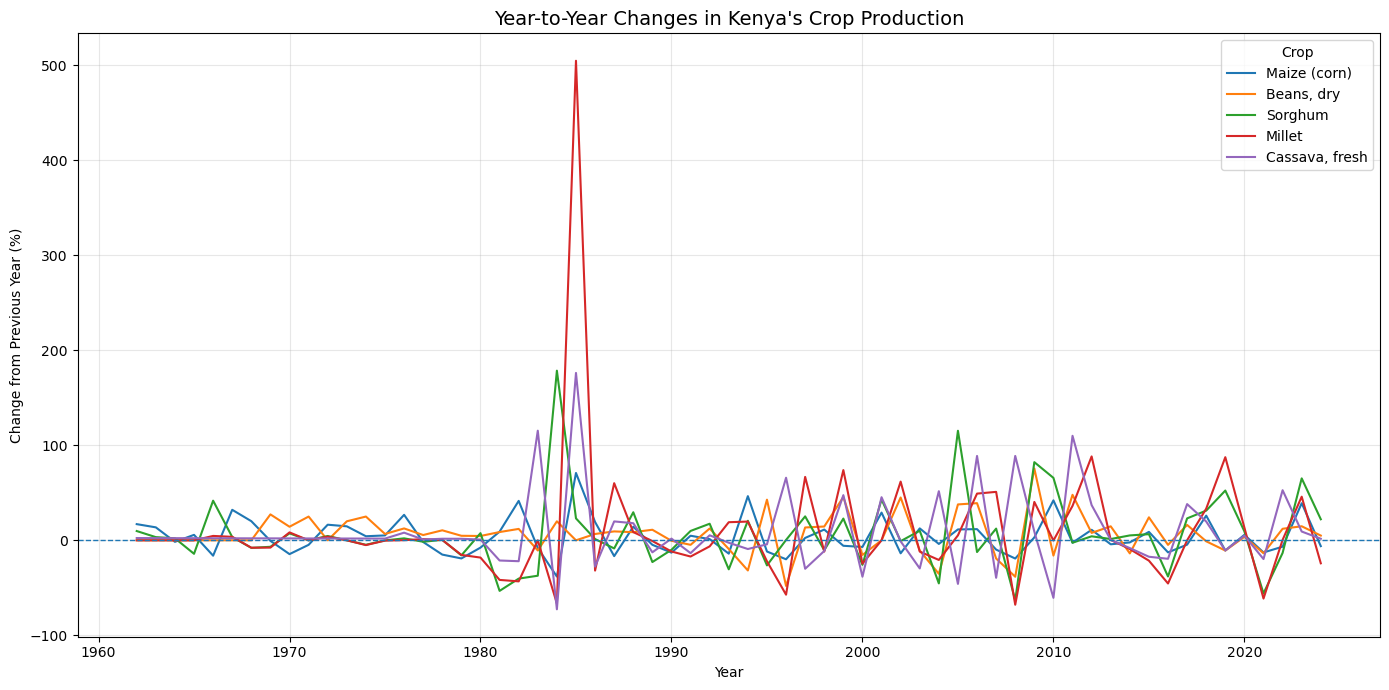

In [14]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

for crop in selected_crops:
    crop_data = production_trends[
        production_trends["Item"] == crop
    ]

    plt.plot(
        crop_data["Year"],
        crop_data["Annual_Change_Pct"],
        label=crop,
        linewidth=1.5
    )

plt.axhline(0, linewidth=1, linestyle="--")
plt.title(
    "Year-to-Year Changes in Kenya's Crop Production",
    fontsize=14
)
plt.xlabel("Year")
plt.ylabel("Change from Previous Year (%)")
plt.legend(title="Crop")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


What we can conclude
- Millet has the highest measured volatility: 71.89%. Its average absolute annual change is also the highest, at 30.79%. This makes millet a priority for further investigation.
- Cassava and sorghum also fluctuate substantially: their volatility standard deviations are 41.25% and 38.25%, respectively.
- Maize and dry beans show lower relative volatility: 19.10% and 21.19%. In this measure, their year-to-year percentage changes are less dispersed.
One caution: millet's average annual percentage change is positive at 10.11%, even though its production in 2024 was lower than in 1961. This is possible because the mean of annual percentage changes is not the same as the compound growth rate over the full period. Large increases and decreases can also produce a positive arithmetic mean while the endpoint is lower.
These are national production statistics, so they don't tell us directly whether individual farmers experienced more or less resilience.

Step 6.3 — Investigate the largest annual changes
Before turning these findings into recommendations, let's identify the specific years behind the biggest fluctuations. This will help us distinguish isolated spikes from recurring patterns.

In [15]:

# Rank the largest annual increases and decreases for each crop
annual_changes = production_trends.dropna(
    subset=["Annual_Change_Pct"]
).copy()

annual_changes["Previous_Year_Production"] = (
    annual_changes.groupby("Item")["Value"].shift(1)
)

# Largest absolute percentage changes across all selected crops
largest_changes = annual_changes.loc[
    annual_changes["Annual_Change_Pct"].abs().nlargest(15).index,
    [
        "Item",
        "Year",
        "Previous_Year_Production",
        "Value",
        "Annual_Change_Pct"
    ]
].sort_values(
    "Annual_Change_Pct",
    key=lambda x: x.abs(),
    ascending=False
)

display(largest_changes.round(2))


,Item,Year,Previous_Year_Production,Value,Annual_Change_Pct
360477,Millet,1985,10000.0,60480.0,504.80
345860,Sorghum,1984,35000.0,97500.0,178.57
360350,"Cassava, fresh",1985,230000.0,635245.0,176.19
330850,"Cassava, fresh",1983,390000.0,840000.0,115.38
655610,Sorghum,2005,69508.0,149656.0,115.31
743850,"Cassava, fresh",2011,323389.0,679167.0,110.02
699600,"Cassava, fresh",2008,397705.0,750964.0,88.82
670100,"Cassava, fresh",2006,347819.0,656633.0,88.79
758727,Millet,2012,73396.0,138204.0,88.30
861977,Millet,2019,72000.0,135000.0,87.50


1. What the results tell us
Finding	Evidence from your table	Interpretation
Largest increase	Millet, 1985: +504.80%	Production rose from 10,000 to 60,480 tonnes. The low starting value magnifies the percentage change.
Another large increase	Sorghum, 1984: +178.57%	Production rose from 35,000 to 97,500 tonnes.
Large cassava fluctuations	1983–1985 and several later years	Cassava production changes substantially across some consecutive years.
Largest decrease shown	Cassava, 1984: −72.62%	Production fell from 840,000 to 230,000 tonnes, then rose sharply in 1985.
Maize increase	1985: +70.89%	Production rose from 1,422,000 to 2,430,000 tonnes.
These are observed changes, not explanations for those changes. We cannot yet conclude that drought, conflict, changes in farming practices, or reporting errors caused them.
The cassava sequence is especially worth checking: production falls sharply in 1984 and then rises in 1985. That pattern could reflect actual production changes, data revisions, estimation methods, or other factors. We need supporting evidence before choosing an explanation.

check the FAOSTAT observation flags
Before deciding whether these spikes are data-quality problems, let's check whether the original FAOSTAT flag file marks the affected observations as estimated, imputed, official, or missing.

In [16]:
import zipfile
import pandas as pd

zip_path = "Production_Crops_Livestock_E_Africa.zip"

# Load the original FAOSTAT observation flags
with zipfile.ZipFile(zip_path, "r") as archive:
    flags = pd.read_csv(
        archive.open("Production_Crops_Livestock_E_Flags.csv")
    )

# Identify the annual flag columns, e.g. F1983, F1984, F1985
flag_year_cols = [
    col for col in flags.columns
    if col.startswith("F") and col[1:].isdigit()
]

print("Flag dataset shape:", flags.shape)
print("Example flag columns:", flag_year_cols[:5])

# Convert flags from wide format to long format
flag_id_cols = [
    col for col in flags.columns
    if col not in flag_year_cols
]

flags_long = flags.melt(
    id_vars=flag_id_cols,
    value_vars=flag_year_cols,
    var_name="Year",
    value_name="Observation_Flag"
)

flags_long["Year"] = (
    flags_long["Year"]
    .str.replace("F", "", regex=False)
    .astype(int)
)

# Check flags for the affected production observations
flag_keys = ["Area Code", "Item Code", "Element Code", "Year"]

anomaly_years = [1983, 1984, 1985]

anomaly_flags = production_trends[
    production_trends["Year"].isin(anomaly_years)
].merge(
    flags_long[flag_keys + ["Observation_Flag"]],
    on=flag_keys,
    how="left",
    validate="many_to_one"
)

display(
    anomaly_flags[
        anomaly_flags["Item"].isin(
            ["Millet", "Sorghum", "Cassava, fresh", "Maize (corn)"]
        )
    ][
        [
            "Item",
            "Year",
            "Value",
            "Annual_Change_Pct",
            "Observation_Flag"
        ]
    ].sort_values(["Item", "Year"])
)

Flag dataset shape: (5, 2)
Example flag columns: []


KeyError: "['Area Code', 'Item Code', 'Element Code'] not in index"

In [17]:
# Inspect the columns in both DataFrames
print("PRODUCTION_TRENDS COLUMNS:")
print(production_trends.columns.tolist())

print("\nFLAGS_LONG COLUMNS:")
print(flags_long.columns.tolist())

PRODUCTION_TRENDS COLUMNS:
['Area Code', 'Area Code (M49)', 'Area', 'Item Code', 'Item Code (CPC)', 'Item', 'Element Code', 'Element', 'Unit', 'Year', 'Value', 'Annual_Change_Pct']

FLAGS_LONG COLUMNS:
['Flag', ' Description', 'Year', 'Observation_Flag']


In [18]:
# Inspect a few rows to understand the flag dataset
display(flags_long.head())

print("\nShape:", flags_long.shape)
print("\nColumn names:")
for col in flags_long.columns:
    print(repr(col))

,Flag,Description,Year,Observation_Flag



Shape: (0, 4)

Column names:
'Flag'
' Description'
'Year'
'Observation_Flag'


In [19]:
import pandas as pd
import zipfile
from pathlib import Path

zip_path = Path("Production_Crops_Livestock_E_Africa.zip")

# 1. Load the original FAOSTAT file WITH observation flags
with zipfile.ZipFile(zip_path, "r") as archive:
    with archive.open("Production_Crops_Livestock_E_Africa.csv") as file:
        df_flags = pd.read_csv(file, low_memory=False)

print("Original flag dataset shape:", df_flags.shape)
print("\nOriginal columns:")
print(df_flags.columns.tolist())

# 2. Identify annual flag columns (F1961, F1962, ...)
flag_year_cols = [
    col for col in df_flags.columns
    if col.startswith("F") and col[1:].isdigit()
]

print("\nNumber of annual flag columns:", len(flag_year_cols))
print("First five flag columns:", flag_year_cols[:5])

# 3. Keep identifiers and annual flags
id_cols = [col for col in df_flags.columns if col not in flag_year_cols]

# 4. Reshape annual flags into long format
flags_long = df_flags.melt(
    id_vars=id_cols,
    value_vars=flag_year_cols,
    var_name="Flag_Year",
    value_name="Observation_Flag"
)

# 5. Extract the year and standardize flag values
flags_long["Year"] = (
    flags_long["Flag_Year"]
    .str.replace("F", "", regex=False)
    .astype(int)
)

flags_long["Observation_Flag"] = (
    flags_long["Observation_Flag"]
    .replace(r"^\s*$", pd.NA, regex=True)
)

# 6. Keep only records that have an observation flag
flags_long = flags_long.dropna(
    subset=["Observation_Flag"]
).copy()

print("\nReshaped flags dataset shape:", flags_long.shape)
display(flags_long.head())

Original flag dataset shape: (14750, 201)

Original columns:
['Area Code', 'Area Code (M49)', 'Area', 'Item Code', 'Item Code (CPC)', 'Item', 'Element Code', 'Element', 'Unit', 'Y1961', 'Y1961F', 'Y1961N', 'Y1962', 'Y1962F', 'Y1962N', 'Y1963', 'Y1963F', 'Y1963N', 'Y1964', 'Y1964F', 'Y1964N', 'Y1965', 'Y1965F', 'Y1965N', 'Y1966', 'Y1966F', 'Y1966N', 'Y1967', 'Y1967F', 'Y1967N', 'Y1968', 'Y1968F', 'Y1968N', 'Y1969', 'Y1969F', 'Y1969N', 'Y1970', 'Y1970F', 'Y1970N', 'Y1971', 'Y1971F', 'Y1971N', 'Y1972', 'Y1972F', 'Y1972N', 'Y1973', 'Y1973F', 'Y1973N', 'Y1974', 'Y1974F', 'Y1974N', 'Y1975', 'Y1975F', 'Y1975N', 'Y1976', 'Y1976F', 'Y1976N', 'Y1977', 'Y1977F', 'Y1977N', 'Y1978', 'Y1978F', 'Y1978N', 'Y1979', 'Y1979F', 'Y1979N', 'Y1980', 'Y1980F', 'Y1980N', 'Y1981', 'Y1981F', 'Y1981N', 'Y1982', 'Y1982F', 'Y1982N', 'Y1983', 'Y1983F', 'Y1983N', 'Y1984', 'Y1984F', 'Y1984N', 'Y1985', 'Y1985F', 'Y1985N', 'Y1986', 'Y1986F', 'Y1986N', 'Y1987', 'Y1987F', 'Y1987N', 'Y1988', 'Y1988F', 'Y1988N', 'Y1989', 'Y

,Area Code,Area Code (M49),Area,Item Code,Item Code (CPC),Item,Element Code,Element,Unit,Y1961,...,Y2022N,Y2023,Y2023F,Y2023N,Y2024,Y2024F,Y2024N,Flag_Year,Observation_Flag,Year


In [20]:
print(flags_long.columns.tolist())

['Area Code', 'Area Code (M49)', 'Area', 'Item Code', 'Item Code (CPC)', 'Item', 'Element Code', 'Element', 'Unit', 'Y1961', 'Y1961F', 'Y1961N', 'Y1962', 'Y1962F', 'Y1962N', 'Y1963', 'Y1963F', 'Y1963N', 'Y1964', 'Y1964F', 'Y1964N', 'Y1965', 'Y1965F', 'Y1965N', 'Y1966', 'Y1966F', 'Y1966N', 'Y1967', 'Y1967F', 'Y1967N', 'Y1968', 'Y1968F', 'Y1968N', 'Y1969', 'Y1969F', 'Y1969N', 'Y1970', 'Y1970F', 'Y1970N', 'Y1971', 'Y1971F', 'Y1971N', 'Y1972', 'Y1972F', 'Y1972N', 'Y1973', 'Y1973F', 'Y1973N', 'Y1974', 'Y1974F', 'Y1974N', 'Y1975', 'Y1975F', 'Y1975N', 'Y1976', 'Y1976F', 'Y1976N', 'Y1977', 'Y1977F', 'Y1977N', 'Y1978', 'Y1978F', 'Y1978N', 'Y1979', 'Y1979F', 'Y1979N', 'Y1980', 'Y1980F', 'Y1980N', 'Y1981', 'Y1981F', 'Y1981N', 'Y1982', 'Y1982F', 'Y1982N', 'Y1983', 'Y1983F', 'Y1983N', 'Y1984', 'Y1984F', 'Y1984N', 'Y1985', 'Y1985F', 'Y1985N', 'Y1986', 'Y1986F', 'Y1986N', 'Y1987', 'Y1987F', 'Y1987N', 'Y1988', 'Y1988F', 'Y1988N', 'Y1989', 'Y1989F', 'Y1989N', 'Y1990', 'Y1990F', 'Y1990N', 'Y1991', 'Y199

I can see the problem now. Your original FAOSTAT file uses three columns per year:
- Y1985 — the numerical value
- Y1985F — the observation flag
- Y1985N — the note or additional metadata
Our previous code selected columns starting with F, but the flags actually start with Y and end with F. That's why flags_long ended up empty. Let's correct this.
Rebuild the observation flags
Next cell: It uses your existing df_flags DataFrame, so you don't need to reload the ZIP file.

In [21]:

# 1. Identify annual observation-flag columns, e.g. Y1985F
flag_year_cols = [
    col for col in df_flags.columns
    if col.startswith("Y")
    and col.endswith("F")
    and col[1:-1].isdigit()
]

print("Number of flag columns:", len(flag_year_cols))
print("First five:", flag_year_cols[:5])
print("Last five:", flag_year_cols[-5:])

# 2. Keep the four identifiers needed for the merge
flag_keys = ["Area Code", "Item Code", "Element Code"]

# 3. Reshape the annual flag columns into long format
flags_long = df_flags[
    flag_keys + flag_year_cols
].melt(
    id_vars=flag_keys,
    value_vars=flag_year_cols,
    var_name="Flag_Year",
    value_name="Observation_Flag"
)

# 4. Convert Y1985F into the integer year 1985
flags_long["Year"] = (
    flags_long["Flag_Year"]
    .str.extract(r"Y(\d{4})F")[0]
    .astype(int)
)

# 5. Remove blank flags, preserving valid flag codes
flags_long["Observation_Flag"] = (
    flags_long["Observation_Flag"]
    .replace(r"^\s*$", pd.NA, regex=True)
)

flags_long = flags_long.dropna(
    subset=["Observation_Flag"]
).copy()

print("\nRebuilt flags_long shape:", flags_long.shape)
print("\nFlag counts:")
display(flags_long["Observation_Flag"].value_counts(dropna=False))

display(flags_long.head())


Number of flag columns: 64
First five: ['Y1961F', 'Y1962F', 'Y1963F', 'Y1964F', 'Y1965F']
Last five: ['Y2020F', 'Y2021F', 'Y2022F', 'Y2023F', 'Y2024F']

Rebuilt flags_long shape: (821048, 6)

Flag counts:


Observation_Flag
E    420605
A    225796
I    135244
M     20291
X     19112
Name: count, dtype: int64

,Area Code,Item Code,Element Code,Flag_Year,Observation_Flag,Year
0,4,221,5312,Y1961F,E,1961
1,4,221,5412,Y1961F,E,1961
2,4,221,5510,Y1961F,A,1961
3,4,515,5312,Y1961F,E,1961
4,4,515,5412,Y1961F,E,1961


Step 6 — Check the results

In [22]:

anomaly_years = [1983, 1984, 1985]

anomaly_flags = production_trends[
    production_trends["Year"].isin(anomaly_years)
].merge(
    flags_long[
        ["Area Code", "Item Code", "Element Code",
         "Year", "Observation_Flag"]
    ],
    on=["Area Code", "Item Code", "Element Code", "Year"],
    how="left",
    validate="many_to_one"
)

display(
    anomaly_flags[
        anomaly_flags["Item"].isin(
            ["Millet", "Sorghum", "Cassava, fresh", "Maize (corn)"]
        )
    ][
        ["Item", "Year", "Value", "Annual_Change_Pct",
         "Observation_Flag"]
    ].sort_values(["Item", "Year"])
)


,Item,Year,Value,Annual_Change_Pct,Observation_Flag
3,"Cassava, fresh",1983,840000.0,115.384615,A
4,"Cassava, fresh",1984,230000.0,-72.619048,A
5,"Cassava, fresh",1985,635245.0,176.193478,A
6,Maize (corn),1983,2300000.0,-8.073541,A
7,Maize (corn),1984,1422000.0,-38.173913,A
8,Maize (corn),1985,2430000.0,70.886076,A
9,Millet,1983,29800.0,0.000000,A
10,Millet,1984,10000.0,-66.442953,A
11,Millet,1985,60480.0,504.800000,A
12,Sorghum,1983,35000.0,-37.275986,A


Your results show that most of the unusual values in this period carry the flag A (Official figure). Sorghum in 1985 carries E (Estimated value).
Crop	Year	Annual change	Flag	Interpretation
Millet	1985	+504.80%	A	Extremely large rebound from a low baseline
Sorghum	1984	+178.57%	A	Large increase from the previous year
Cassava	1984	−72.62%	A	Large decline
Cassava	1985	+176.19%	A	Large rebound
Maize	1984	−38.17%	A	Substantial decline
Maize	1985	+70.89%	A	Substantial rebound
Sorghum	1985	+23.08%	E	Increase based on an estimated observation
Key finding: the flags do not, by themselves, explain the fluctuations. An official figure can still reflect a real change, measurement uncertainty, or a historical data limitation. We should not label these anomalies as errors without further evidence.

Millet is particularly worth investigating: production rose from 10,000 tonnes in 1984 to 60,480 tonnes in 1985. Because the starting value was low, the percentage increase is especially large.

Step 7.1 — Determine what drove the production changes
Before we move on, let's check whether the unusual production movements coincided with changes in harvested area, yield, or both. This will make our analysis more useful than simply ranking percentage changes.

In [23]:

# Inspect production, harvested area, and yield for 1983–1985
anomaly_crops = [
    "Millet",
    "Sorghum",
    "Cassava, fresh",
    "Maize (corn)"
]

anomaly_detail = df_crop[
    df_crop["Item"].isin(anomaly_crops)
    & df_crop["Year"].isin([1982, 1983, 1984, 1985, 1986])
].copy()

# Attach the observation flags for each crop, measure, and year
anomaly_detail = anomaly_detail.merge(
    flags_long[
        [
            "Area Code",
            "Item Code",
            "Element Code",
            "Year",
            "Observation_Flag"
        ]
    ],
    on=["Area Code", "Item Code", "Element Code", "Year"],
    how="left",
    validate="many_to_one"
)

# Display the measures side by side
anomaly_wide = anomaly_detail.pivot(
    index=["Item", "Year"],
    columns="Element",
    values="Value"
).reset_index()

anomaly_wide.columns.name = None

display(
    anomaly_wide.sort_values(["Item", "Year"]).round(2)
)


,Item,Year,Area harvested,Production,Yield
0,"Cassava, fresh",1982,75000.0,390000.0,5200.0
1,"Cassava, fresh",1983,84000.0,840000.0,10000.0
2,"Cassava, fresh",1984,46000.0,230000.0,5000.0
3,"Cassava, fresh",1985,50000.0,635245.0,12704.9
4,"Cassava, fresh",1986,53885.0,459450.0,8526.5
5,Maize (corn),1982,1208000.0,2502000.0,2071.2
6,Maize (corn),1983,1300000.0,2300000.0,1769.2
7,Maize (corn),1984,985000.0,1422000.0,1443.7
8,Maize (corn),1985,1411000.0,2430000.0,1722.2
9,Maize (corn),1986,1424600.0,2898000.0,2034.3


Interpretation of the 1982–1986 results
Millet
Largest rebound
Production fell from 29,800 tonnes in 1983 to 10,000 tonnes in 1984, while harvested area declined from 46,660 to 29,000 hectares and yield fell from 638.7 to 344.8 kg/ha. In 1985, both area and yield recovered, accompanying the production increase to 60,480 tonnes.


Cassava
Production moved from 840,000 tonnes in 1983 to 230,000 tonnes in 1984, then rose to 635,245 tonnes in 1985. Harvested area and yield both fell in 1984 and rose in 1985, so both measures moved in the same direction as production.

Maize
Production declined from 2.50 million tonnes in 1982 to 1.42 million tonnes in 1984. Both harvested area and yield fell over this period. In 1985, both increased, alongside production recovering to 2.43 million tonnes.

Sorghum
Production fell from 55,800 tonnes in 1982 to 35,000 tonnes in 1983 even though harvested area increased. Yield fell sharply from 644.3 to 291.7 kg/ha, making yield a key numerical contributor to that decline. Production then recovered as yield and area increased.

These are descriptive relationships in the reported data. They do not establish why area or yield changed.
2. One important quality check
Millet's production is identical in 1982 and 1983 — 29,800 tonnes — and its area and yield are also identical. That is worth recording for review, but it is not proof of a data error.

Let's quantify how much area and yield changed during the major production movements, rather than relying only on visual inspection.

Step 7.2 — Calculate year-on-year changes in all three measures

In [24]:
# Sort the selected crop data chronologically
anomaly_detail = anomaly_detail.sort_values(["Item", "Year"]).copy()

# Calculate year-on-year percentage changes for each measure
for measure in ["Production", "Area harvested", "Yield"]:
    anomaly_detail[f"{measure}_Change_Pct"] = (
        anomaly_detail.groupby(["Item", "Element"])[measure]
        .pct_change(fill_method=None) * 100
        if False else float("nan")
    )

# Create one row per crop-year with the three measures
anomaly_wide = df_crop[
    df_crop["Item"].isin(anomaly_crops)
    & df_crop["Year"].between(1982, 1986)
].pivot(
    index=["Item", "Year"],
    columns="Element",
    values="Value"
).reset_index()

anomaly_wide.columns.name = None
anomaly_wide = anomaly_wide.sort_values(["Item", "Year"])

for measure in ["Production", "Area harvested", "Yield"]:
    anomaly_wide[f"{measure}_Change_Pct"] = (
        anomaly_wide.groupby("Item")[measure]
        .pct_change(fill_method=None) * 100
    )

display(
    anomaly_wide[
        [
            "Item", "Year",
            "Production_Change_Pct",
            "Area harvested_Change_Pct",
            "Yield_Change_Pct"
        ]
    ].round(2)
)


,Item,Year,Production_Change_Pct,Area harvested_Change_Pct,Yield_Change_Pct
0,"Cassava, fresh",1982,NaN,NaN,NaN
1,"Cassava, fresh",1983,115.38,12.00,92.31
2,"Cassava, fresh",1984,-72.62,-45.24,-50.00
3,"Cassava, fresh",1985,176.19,8.70,154.10
4,"Cassava, fresh",1986,-27.67,7.77,-32.89
5,Maize (corn),1982,NaN,NaN,NaN
6,Maize (corn),1983,-8.07,7.62,-14.58
7,Maize (corn),1984,-38.17,-24.23,-18.40
8,Maize (corn),1985,70.89,43.25,19.29
9,Maize (corn),1986,19.26,0.96,18.12


### Historical Production Anomaly Investigation (1982–1986)
The investigation of selected crop-production fluctuations identified substantial year-on-year changes in millet, cassava, maize, and sorghum.
- **Millet:** Production increased by 504.80% in 1985 following a 66.44% decline in 1984. The rebound coincided with increases in harvested area (93.10%) and yield (213.23%).
- **Cassava:** Production declined by 72.62% in 1984 and increased by 176.19% in 1985. Changes in both harvested area and yield accompanied these movements.
- **Maize:** The 38.17% production decline in 1984 coincided with decreases in harvested area and yield. Both measures increased in 1985 as production recovered.
- **Sorghum:** Production declined by 37.28% in 1983 despite an increase in harvested area, while yield declined by 54.73%.
The observation-flag review classified most examined observations as official figures, while the 1985 sorghum production figure was estimated. Official status does not guarantee that a figure is error-free, and an estimated value is not necessarily inaccurate.
These findings identify historical fluctuations requiring further investigation. They do not establish the causes of the canges. Production volatility is used as a descriptive indicator of output instability, not as a complete measure of farmer resilience.
**Next steps:** Review the full time series, evaluate data comparability across years, and investigate relevant contextual evidence before making causal claims or recommendations.


One methodological note before moving on: because production is approximately harvested area multiplied by yield, the percentage changes in those two measures should not be added together to explain the production percentage change. Their combined effect is multiplicative

My recommendation: finish Notebook 1 with a concise data-audit summary, then move the deeper analytical work into Notebook 2. That will make the portfolio easier for recruiters to follow and demonstrate a clear, reproducible workflow.